In [26]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [27]:
# Baca file CSV
df = pd.read_csv("PRDB.csv")

In [28]:
# Drop baris pertama karena merupakan header ganda (berisi tahun)
df = df.drop(0).reset_index(drop=True)

In [29]:
#  nama kolom supaya lebih jelas
df.columns = ["Sektor", "2020", "2021", "2022", "2023", "2024"]

In [30]:
# Konversi data ke tipe numerik
for col in ["2020", "2021", "2022", "2023", "2024"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [31]:
# Hapus baris  nilai kosong
df = df.dropna().reset_index(drop=True)

In [32]:
#  Persiapan Variabel untuk Prediksi ---
df_sektoral = df[df['Sektor'] != 'PDRB'].copy()
tahun_data = np.array([2020, 2021, 2022, 2023, 2024]).reshape(-1, 1)
tahun_prediksi = np.array([2025, 2026]).reshape(-1, 1)
n = len(tahun_data) # Jumlah data historis
hasil_analisis = {}

In [33]:
#  Analisis dan Prediksi untuk Setiap Sektor ---
print("⏳ Memulai analisis regresi dan prediksi komprehensif...")
for index, row in df_sektoral.iterrows():
    nama_sektor = row['Sektor']
    nilai_pdrb = row[["2020", "2021", "2022", "2023", "2024"]].values
    
    model = LinearRegression()
    model.fit(tahun_data, nilai_pdrb)

⏳ Memulai analisis regresi dan prediksi komprehensif...


In [34]:
# (LOOPING, ANALISIS & PREDIKSI) ---
if df is not None:
    df_sektoral = df[df['Sektor'] != 'PDRB'].copy()
    tahun_data = np.array([2020, 2021, 2022, 2023, 2024]).reshape(-1, 1)
    tahun_prediksi = np.array([2025, 2026]).reshape(-1, 1)
    n = len(tahun_data)
    hasil_analisis = {}

    print("⏳ Memulai analisis regresi dan prediksi komprehensif...")

    for index, row in df_sektoral.iterrows():
        nama_sektor = row['Sektor']
        nilai_pdrb = row[["2020", "2021", "2022", "2023", "2024"]].values

        model = LinearRegression()
        model.fit(tahun_data, nilai_pdrb)

        # Evaluasi Model
        prediksi_historis = model.predict(tahun_data)
        r2 = r2_score(nilai_pdrb, prediksi_historis)
        rmse = np.sqrt(np.mean((nilai_pdrb - prediksi_historis) ** 2))
        mae = np.mean(np.abs(nilai_pdrb - prediksi_historis))

        # Interpretasi Model
        laju_pertumbuhan = model.coef_[0]

        # Prediksi Masa Depan
        prediksi_masa_depan = model.predict(tahun_prediksi)

        # Simpan hasil
        hasil_analisis[nama_sektor] = {
            'Prediksi 2025': prediksi_masa_depan[0],
            'Prediksi 2026': prediksi_masa_depan[1],
            'Laju Pertumbuhan Tahunan': laju_pertumbuhan,
            'R-Squared': r2,
            'RMSE': rmse,
            'MAE': mae
        }

    print("✅ Proses analisis dan prediksi selesai.")
else:
    print("❗️ Proses dihentikan karena data tidak berhasil dimuat.")


⏳ Memulai analisis regresi dan prediksi komprehensif...
✅ Proses analisis dan prediksi selesai.


In [35]:
# MENYUSUN DAN MENAMPILKAN LAPORAN ---
if 'hasil_analisis' in locals():
    # Ubah dictionary hasil analisis menjadi DataFrame
    df_hasil = pd.DataFrame.from_dict(hasil_analisis, orient='index')

    # Gabungkan data asli dengan hasil analisis
    df_asli_indexed = df.set_index('Sektor')
    df_laporan_final = pd.concat([df_asli_indexed, df_hasil], axis=1)

    # Hitung ulang total PDRB
    df_laporan_final.loc['PDRB', 'Prediksi 2025'] = df_laporan_final['Prediksi 2025'].sum()
    df_laporan_final.loc['PDRB', 'Prediksi 2026'] = df_laporan_final['Prediksi 2026'].sum()

    print("\n" + "="*110)
    print("                       LAPORAN LENGKAP: ANALISIS TREN DAN PREDIKSI PDRB")
    print("="*110)
    kolom_tampil = ['2024', 'Prediksi 2025', 'Prediksi 2026', 'Laju Pertumbuhan Tahunan', 'R-Squared', 'RMSE', 'MAE']
    print(df_laporan_final[kolom_tampil].to_string(float_format="%.2f"))
else:
    print("❗️ Variabel 'hasil_analisis' tidak ditemukan. Pastikan sel sebelumnya sudah dijalankan.")



                       LAPORAN LENGKAP: ANALISIS TREN DAN PREDIKSI PDRB
                                                                          2024  Prediksi 2025  Prediksi 2026  Laju Pertumbuhan Tahunan  R-Squared       RMSE       MAE
A. Pertanian Kehutanan, dan Perikanan                                421692.95      422104.25      434184.06                  12079.81       0.80    8453.95   7901.05
B. Pertambangan dan Penggalian                                            0.00           0.00           0.00                      0.00       1.00       0.00      0.00
C. Industri Pengolahan                                             33271888.80    35845825.62    37792294.49                1946468.87       0.94  671189.74 607703.48
D. Pengadaan Listrik dan Gas                                         772149.19      688773.76      580256.43                -108517.33       0.93   40949.97  37322.61
E. Pengadaan Air, Pengelolaan Sampah, Limbah dan Daur Ulang          227640.12      234233.7

In [36]:
pip install pymysql

Note: you may need to restart the kernel to use updated packages.


In [37]:
###  MEMBUAT DUA DATAFRAME TERPISAH (PREDIKSI & EVALUASI) 

# Pastikan variabel df_hasil dan df dari sel sebelumnya sudah ada
if 'df_hasil' in locals() and 'df' in locals():
    print("⏳ Memisahkan data menjadi tabel prediksi dan evaluasi...")

    # 1.1. DataFrame untuk EVALUASI MODEL
    kolom_evaluasi = ['Laju Pertumbuhan Tahunan', 'R-Squared', 'RMSE', 'MAE']
    df_evaluasi_model = df_hasil[kolom_evaluasi]
    
    # 1.2. DataFrame untuk PREDIKSI
    df_prediksi_final = df.set_index('Sektor').join(df_hasil[['Prediksi 2025', 'Prediksi 2026']])
    
    df_prediksi_final.loc['PDRB', 'Prediksi 2025'] = df_prediksi_final['Prediksi 2025'].sum()
    df_prediksi_final.loc['PDRB', 'Prediksi 2026'] = df_prediksi_final['Prediksi 2026'].sum()
    
    print("✅ Dua DataFrame terpisah (prediksi dan evaluasi) berhasil dibuat.")

    
    ### TAMBAHAN 2: MENYIMPAN KEDUA DATAFRAME KE DATABASE MYSQL MENGGUNAKAN PYMYSQL ###
    
    from sqlalchemy import create_engine
    import warnings
    
    warnings.filterwarnings('ignore', message='The provided table name .* is not found exactly as such in the database')

    try:
        # --- PERUBAHAN UTAMA ADA DI SINI ---
        # Menggunakan pymysql sebagai driver koneksi
        engine = create_engine("mysql+pymysql://root:@localhost/db_pdrb")
        # ------------------------------------
        
        # Nama tabel yang akan dibuat
        tabel_prediksi = 'prediksi_pdrb'
        tabel_evaluasi = 'evaluasi_model_pdrb'
        
        print(f"\n⏳ Menyambungkan dan menyimpan data ke database 'db_pdrb' menggunakan pymysql...")
        
        # Menyimpan DataFrame Prediksi
        df_prediksi_final.to_sql(
            name=tabel_prediksi,
            con=engine,
            if_exists='replace',
            index=True
        )
        print(f"  -> ✅ Tabel '{tabel_prediksi}' berhasil disimpan.")
        
        # Menyimpan DataFrame Evaluasi
        df_evaluasi_model.to_sql(
            name=tabel_evaluasi,
            con=engine,
            if_exists='replace',
            index=True
        )
        print(f"  -> ✅ Tabel '{tabel_evaluasi}' berhasil disimpan.")
        
        print("\n🎉 Proses selesai! Silakan periksa PHPMyAdmin untuk melihat kedua tabel baru.")

    except Exception as e:
        print("\n❌ GAGAL MENYIMPAN KE DATABASE.")
        print("   Pastikan driver 'pymysql' sudah terinstal (`pip install pymysql`).")
        print(f"   Detail Error: {e}")

else:
    print("❗️ Variabel yang dibutuhkan tidak ditemukan. Pastikan sel-sel sebelumnya sudah dijalankan.")

⏳ Memisahkan data menjadi tabel prediksi dan evaluasi...
✅ Dua DataFrame terpisah (prediksi dan evaluasi) berhasil dibuat.

⏳ Menyambungkan dan menyimpan data ke database 'db_pdrb' menggunakan pymysql...
  -> ✅ Tabel 'prediksi_pdrb' berhasil disimpan.
  -> ✅ Tabel 'evaluasi_model_pdrb' berhasil disimpan.

🎉 Proses selesai! Silakan periksa PHPMyAdmin untuk melihat kedua tabel baru.


In [38]:
# --- SEL TAMBAHAN: MEMBUAT TABEL LONG FORMAT UNTUK METABASE ---
if 'df_prediksi_final' in locals():
    print("⏳ Membuat tabel 'long format' untuk visualisasi...")

    # Ambil DataFrame prediksi yang sudah jadi
    df_long = df_prediksi_final.reset_index()

    # Gunakan 'melt' untuk mengubah format dari wide ke long
    df_long = df_long.melt(
        id_vars='Sektor',
        value_vars=['2020', '2021', '2022', '2023', '2024', 'Prediksi 2025', 'Prediksi 2026'],
        var_name='Tahun',
        value_name='PDRB'
    )

    # Tambahkan kolom 'Status' untuk membedakan data asli dan prediksi
    df_long['Tahun'] = df_long['Tahun'].str.replace('Prediksi ', '').astype(int)
    df_long['Status'] = np.where(df_long['Tahun'] > 2024, 'Prediksi', 'Historis')
    
    # Simpan ke database
    try:
        engine = create_engine('mysql+pymysql://root:@localhost/db_pdrb')
        nama_tabel_long = 'prediksi_pdrb_long'
        df_long.to_sql(name=nama_tabel_long, con=engine, if_exists='replace', index=False)
        print(f"✅ Tabel '{nama_tabel_long}' berhasil disimpan ke MySQL. Gunakan tabel ini di Metabase!")
    except Exception as e:
        print(f"❌ Gagal menyimpan tabel long format. Error: {e}")
else:
    print("❗️ Variabel 'df_prediksi_final' tidak ditemukan.")

⏳ Membuat tabel 'long format' untuk visualisasi...
✅ Tabel 'prediksi_pdrb_long' berhasil disimpan ke MySQL. Gunakan tabel ini di Metabase!


In [39]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



⏳ Membuat visualisasi heatmap untuk analisis laju pertumbuhan...


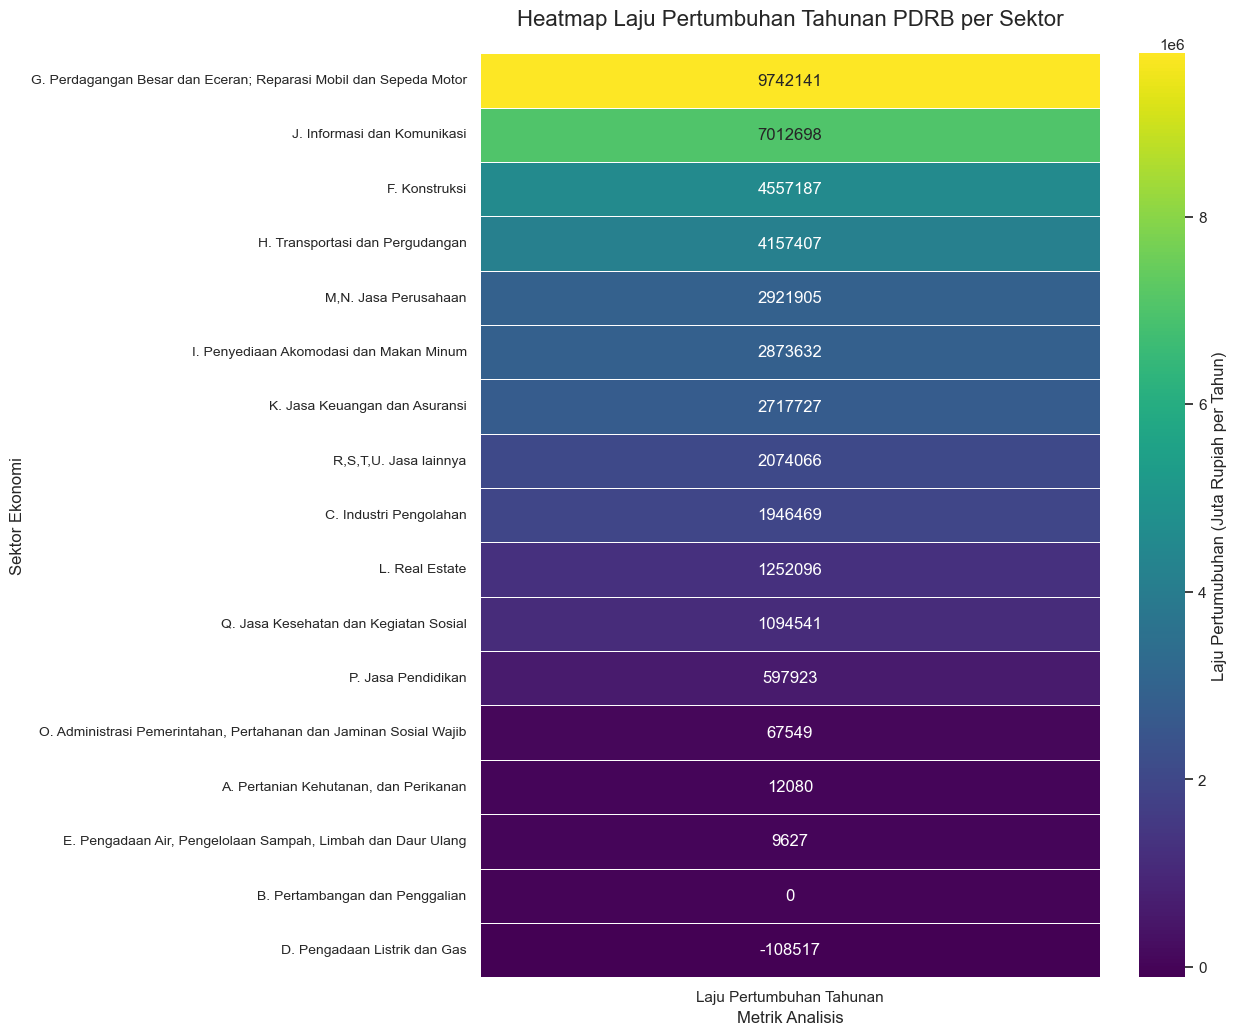

✅ Heatmap berhasil dibuat dan disimpan sebagai 'heatmap_laju_pertumbuhan.png'.


In [40]:

# Pastikan df_laporan_final sudah ada dari sel sebelumnya
if 'df_laporan_final' in locals():
    print("\n⏳ Membuat visualisasi heatmap untuk analisis laju pertumbuhan...")

    # Impor library yang dibutuhkan
    import matplotlib.pyplot as plt
    import seaborn as sns

    # Mengatur style visualisasi agar lebih menarik
    sns.set_theme(style="whitegrid")

    # 1. Persiapan Data untuk Heatmap
    # Kita akan fokus pada Laju Pertumbuhan Tahunan, dan kita perlu menghapus baris PDRB total
    # serta baris lain yang mungkin tidak memiliki data laju pertumbuhan.
    df_heatmap_data = df_laporan_final[['Laju Pertumbuhan Tahunan']].dropna().sort_values(
        by='Laju Pertumbuhan Tahunan', ascending=False
    )

    #  Plot Heatmap
    plt.figure(figsize=(10, 12))  # Mengatur ukuran gambar agar lebih tinggi dan mudah dibaca

    heatmap_plot = sns.heatmap(
        df_heatmap_data,
        annot=True,          # Menampilkan nilai angka di dalam setiap sel
        fmt='.0f',           # Format angka menjadi integer (tanpa desimal)
        cmap='viridis',      # Skema warna, 'viridis' bagus untuk menunjukkan gradasi dari rendah (ungu) ke tinggi (kuning)
        linewidths=.5,       # Memberi garis tipis antar sel
        cbar_kws={'label': 'Laju Pertumubuhan (Juta Rupiah per Tahun)'} # Label untuk color bar
    )

    #  Judul dan Label
    plt.title('Heatmap Laju Pertumbuhan Tahunan PDRB per Sektor', fontsize=16, pad=20)
    plt.xlabel('Metrik Analisis', fontsize=12)
    plt.ylabel('Sektor Ekonomi', fontsize=12)
    plt.xticks(rotation=0) # Agar label x tidak miring
    plt.yticks(fontsize=10)

    # 4. Menyimpan Gambar dan Menampilkan
    nama_file_gambar = 'heatmap_laju_pertumbuhan.png'
    plt.savefig(
        nama_file_gambar,
        dpi=300,  # Resolusi tinggi untuk laporan
        bbox_inches='tight' # Memastikan semua label pas di dalam gambar
    )

    plt.show() # Menampilkan plot di output notebook/skrip

    print(f"✅ Heatmap berhasil dibuat dan disimpan sebagai '{nama_file_gambar}'.")

else:
    print("❗️ Variabel 'df_laporan_final' tidak ditemukan. Pastikan sel sebelumnya sudah dijalankan.")